# Exercises XP — Diabetes Classification

In these exercises, I build a Logistic Regression model that predicts if an individual has diabetes. I follow the course's pre-filled Colab notebook and complete its TODO parts.

### What I learn here
- Understanding the problem
- Data collection
- Model training for a classification problem
- Evaluating my model

## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. I download `Diabetes prediction dataset.zip` from the [course link](https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%204/Day%202/Diabetes%20prediction%20dataset.zip) into my `C:\Users\sivan\Datasets` folder (it is already there).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `Diabetes prediction dataset.zip`.

In [ ]:
from google.colab import files
# I import Colab's tool for uploading files from my computer.
uploaded = files.upload()
# I open a file picker and choose "Diabetes prediction dataset.zip".
!unzip "Diabetes prediction dataset.zip"
# I extract diabetes_prediction_dataset.csv from the zip into Colab.

## 🌟 Exercise 1 : Understanding the problem and Data Collection

In this exercise, I want to predict if an individual has diabetes. I load the diabetes dataset and explore it, I count how many positive and negative cases there are, and I split the data into training and testing sets.

### What I learn here
- I explore a new dataset: its size, first rows, column types and missing values.
- I count the positive and negative cases of the target.
- I split the data into a training set and a testing set.

In [1]:
import pandas as pd

# I read the CSV file that I extracted from the zip.
df = pd.read_csv('diabetes_prediction_dataset.csv')

# I print the number of rows and columns.
print(df.shape)
# I show the first 5 rows.
display(df.head())
# I print the type of each column (numbers or text).
print(df.dtypes)
print("Missing per column:")
# I count the missing values in each column, largest first.
display(df.isna().sum().sort_values(ascending=False))

(100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object
Missing per column:


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [2]:
# I check that the target column 'diabetes' exists (0 = no diabetes, 1 = diabetes).
assert 'diabetes' in df.columns, "Expected a 'diabetes' target column"
# I count the negative (0) and positive (1) cases.
print(df['diabetes'].value_counts())
# I show the same counts as a share of all rows.
print(df['diabetes'].value_counts(normalize=True).round(3))

diabetes
0    91500
1     8500
Name: count, dtype: int64
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64


**My answer:** From the counts printed above, there are **91,500 negative cases** (diabetes = 0) and **8,500 positive cases** (diabetes = 1), so only 8.5% of the 100,000 people have diabetes. The data is imbalanced, which is why I use `stratify=y` in the split. The first cell also shows 0 missing values in every column, and two text columns (`gender`, `smoking_history`).

In [3]:
from sklearn.model_selection import train_test_split

# X holds the features (all columns except the answer), y holds the answer.
X = df.drop(columns=['diabetes'])
y = df['diabetes']
# I keep 20% of the rows for testing. stratify=y keeps the same share of positives in both sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(80000, 8) (20000, 8)


## 🌟 Exercise 2 : Model Picking and Standardization

In this exercise, I explain which classification model I can use for this problem and why. Then I check if I need to standardize the data, and if yes, I use `StandardScaler()`.

### What I learn here
- I choose a model that fits a binary (yes/no) problem.
- I see why features on very different scales should be standardized.
- I turn text columns into number columns so the model can use them.

**Which model and why:** The target has only two values (0 = no diabetes, 1 = diabetes), so this is a binary classification problem. I can use **Logistic Regression**:
- It draws a linear decision boundary between the two classes.
- It gives a probability between 0 and 1 for each person, and logistic regression probabilities are usually well calibrated (a predicted 0.8 means about 80% of such people have diabetes).
- It is easy to interpret, because each feature gets one coefficient that pushes the probability up or down.

**Do I need to standardize?** Yes. The table printed below shows very different scales: `blood_glucose_level` goes from 80 to 300 (std 40.66), `age` from 0.08 to 80, but `HbA1c_level` only from 3.5 to 9 (std 1.07). Standardizing puts every number column on the same scale (mean 0, std 1). This helps numerical stability: the solver converges faster and no feature dominates just because its numbers are bigger. So I use `StandardScaler()`. The text columns `gender` and `smoking_history` must become 0/1 columns first, so I one-hot encode them.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# I list the text columns (gender, smoking_history) and the number columns.
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()

# I build the preprocessing step that the course template asks for:
# StandardScaler for the number columns and OneHotEncoder for the text columns.
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])
# By hand, StandardScaler does: (value - training mean) / training standard deviation.
# By hand, OneHotEncoder works like pd.get_dummies(X, columns=cat_cols): one 0/1 column per category.
print("Categorical:", cat_cols)
print("Numeric:", num_cols)

# I print the mean, spread, min and max of the number columns to see if their scales differ.
display(X_train[num_cols].describe().loc[['mean', 'std', 'min', 'max']].round(2))

Categorical: ['gender', 'smoking_history']
Numeric: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
mean,41.90,0.07,0.04,27.32,5.53,138.08
std,22.53,0.26,0.19,6.64,1.07,40.66
min,0.08,0.00,0.00,10.01,3.50,80.00
max,80.00,1.00,1.00,95.69,9.00,300.00


## 🌟 Exercise 3 : Model Training

In this exercise, I use the logistic regression model and I train it.

### What I learn here
- I connect the preprocessing step and the model in one `Pipeline`, as the course template does.
- I fit the scaler and the model on the training rows only.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# The Pipeline first runs my preprocessing step, then the logistic regression.
clf = Pipeline([
    ('pre', preprocess),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])
# I train on the training set only, so the test rows stay unseen.
# The scaler learns its means and standard deviations here, from the training rows.
clf.fit(X_train, y_train)
# I print the two classes the model learned.
print("Classes:", clf.classes_)

Classes: [0 1]


## 🌟 Exercise 4 : Evaluation Metrics

In this exercise, I plot the accuracy score, the confusion matrix, and the recall, precision and F1-score, and I comment on each result.

### What I learn here
- I measure how often my model is right (accuracy).
- I read the four counts of a confusion matrix.
- I use precision, recall and F1 to see how well the model finds the positive cases.

Accuracy: 0.9605
Precision: 0.8587
Recall: 0.64
F1: 0.7334


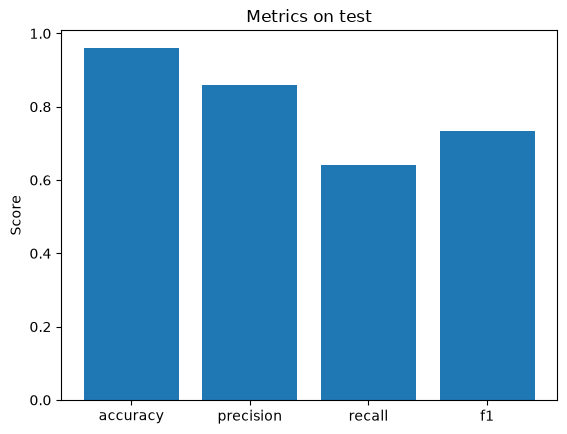

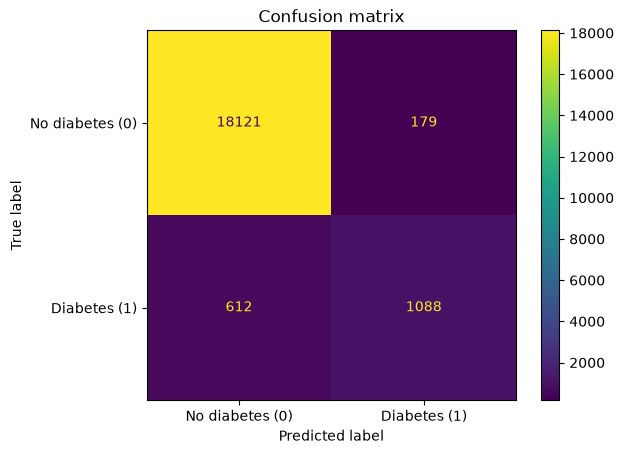

True negatives: 18121 | False positives: 179
False negatives: 612 | True positives: 1088


In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# I predict 0 or 1 for every test row.
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
# By hand: (TP + TN) / all test rows
prec = precision_score(y_test, y_pred)
# By hand: TP / (TP + FP)
rec = recall_score(y_test, y_pred)
# By hand: TP / (TP + FN)
f1 = f1_score(y_test, y_pred)
# By hand: 2 * prec * rec / (prec + rec)

print("Accuracy:", round(acc,4))
print("Precision:", round(prec,4))
print("Recall:", round(rec,4))
print("F1:", round(f1,4))

# Simple bar plot of metrics
plt.figure()
plt.bar(['accuracy','precision','recall','f1'], [acc,prec,rec,f1])
plt.title('Metrics on test')
plt.ylabel('Score')
plt.show()

# Confusion matrix: rows are the true classes, columns are the predicted classes.
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No diabetes (0)', 'Diabetes (1)'])
disp.plot()
plt.title('Confusion matrix')
plt.show()

# I unpack the four counts so I can quote them in my comments.
tn, fp, fn, tp = cm.ravel()
print("True negatives:", tn, "| False positives:", fp)
print("False negatives:", fn, "| True positives:", tp)

**Accuracy:** The printed accuracy is **0.9605**, so the model is right for about 96% of the 20,000 test rows. This sounds very good, but 91.5% of the people have no diabetes (Exercise 1), so a model that always says "no diabetes" would already get 91.5%. Accuracy alone is not enough here.

**Confusion matrix:** From the printed counts:
- **18,121 true negatives**: people without diabetes correctly predicted as 0.
- **179 false positives**: people without diabetes wrongly flagged as diabetic.
- **612 false negatives**: people with diabetes that the model missed.
- **1,088 true positives**: people with diabetes correctly found.

The model is very good at recognizing healthy people, but it misses 612 of the 1,700 diabetic people in the test set.

**Recall, precision, F1:** **Precision is 0.8587**: when the model says "diabetes", it is right about 86% of the time. **Recall is 0.64**: it finds only 64% of the real diabetes cases. **F1 is 0.7334**, which is the balance between the two. Precision is clearly higher than recall, so the model is careful before saying "diabetes" and misses many positive cases. For a medical problem, missing a sick person is usually worse than a false alarm, so I would want a higher recall (for example by lowering the 0.5 cutoff).

## 🌟 Exercise 5 : Visualizing the performance of my model

In this exercise, I visualize the decision boundary of my model with its accuracy. To keep the plot in 2D, the template uses only two informative features: `HbA1c_level` and `blood_glucose_level`.

### What I learn here
- I see the line where the model switches from "no diabetes" to "diabetes".
- I check how accurate a model with only two features is.

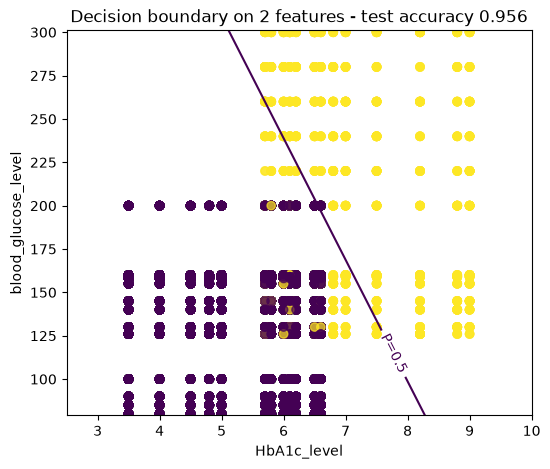

Test accuracy with 2 features: 0.9562


In [7]:
import numpy as np

# I use the two features that the template suggests.
feat_x = 'HbA1c_level' if 'HbA1c_level' in X.columns else X.select_dtypes(include=['int64','float64']).columns[0]
feat_y = 'blood_glucose_level' if 'blood_glucose_level' in X.columns else X.select_dtypes(include=['int64','float64']).columns[1]

# I keep only these two columns from the train and test sets.
X2_train = X_train[[feat_x, feat_y]].copy()
X2_test = X_test[[feat_x, feat_y]].copy()

# A second, smaller model: it scales the 2 columns and fits a logistic regression on them.
pipe2 = Pipeline([
    ('pre', ColumnTransformer([('num', StandardScaler(), [0,1])], remainder='drop')),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])
pipe2.fit(X2_train.values, y_train)

# Mesh: a grid of 300 x 300 (HbA1c, glucose) pairs that covers the whole plot.
x_min, x_max = X2_train[feat_x].min()-1, X2_train[feat_x].max()+1
y_min, y_max = X2_train[feat_y].min()-1, X2_train[feat_y].max()+1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
# I predict the diabetes probability for every grid point and put the results back in grid shape.
probs = pipe2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:,1].reshape(xx.shape)

plt.figure(figsize=(6,5))
# I draw the line where the probability is 0.5. That line is the decision boundary.
cs = plt.contour(xx, yy, probs, levels=[0.5])
# The template wrote fmt={{0.5:'P=0.5'}}, which raises an error, so I use single braces.
plt.clabel(cs, inline=True, fmt={0.5:'P=0.5'})
# I color the test points by their true class (dark = 0, yellow = 1).
plt.scatter(X2_test[feat_x], X2_test[feat_y], c=y_test, alpha=0.7)
plt.xlabel(feat_x); plt.ylabel(feat_y)
acc2 = accuracy_score(y_test, pipe2.predict(X2_test.values))
plt.title(f'Decision boundary on 2 features - test accuracy {acc2:.3f}')
plt.show()
print("Test accuracy with 2 features:", round(acc2, 4))

**My comment:** In the plot, the P=0.5 line is the decision boundary. Points to the left of it (lower HbA1c and glucose) are predicted "no diabetes", and points to the right are predicted "diabetes". The plot shows that every test point with glucose above 200 is yellow (diabetes), and the model gets most of them right. The mistakes are mainly the yellow points with HbA1c around 6 to 7.5 and glucose below 200, which fall on the left side of the line and are missed. The printed test accuracy with only these 2 features is **0.9562**, almost the same as the 0.9605 of my full model in Exercise 4, so HbA1c and blood glucose carry most of the information for predicting diabetes.

## 🌟 Exercise 6 : ROC Curve

In this exercise, I plot the ROC curve with the code template from [Statology](https://www.statology.org/plot-roc-curve-python/) and I compute the AUC.

### What I learn here
- I see how the true positive rate and the false positive rate change when the cutoff changes.
- I read the AUC: 0.5 means random guessing and 1 means perfect.

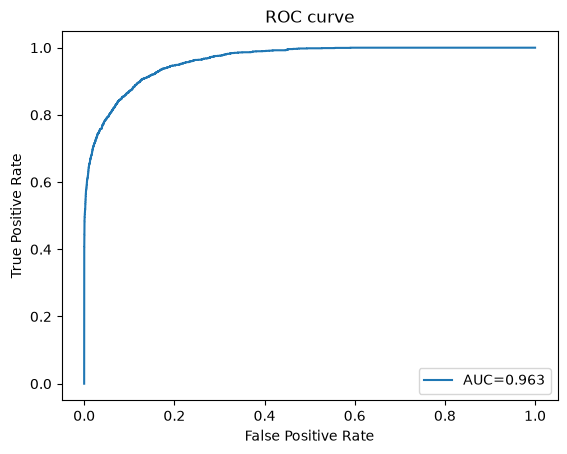

AUC: 0.9625


In [8]:
from sklearn import metrics

# I take column 1 of predict_proba: the probability of diabetes for each test row.
y_proba = clf.predict_proba(X_test)[:,1]
# roc_curve tries many cutoffs and returns the false and true positive rate for each one.
fpr, tpr, _ = metrics.roc_curve(y_test, y_proba)
# AUC is the area under the ROC curve.
auc = metrics.roc_auc_score(y_test, y_proba)

plt.figure()
plt.plot(fpr, tpr, label=f'AUC={auc:.3f}')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.legend(loc=4)
plt.title('ROC curve')
plt.show()
print("AUC:", round(auc, 4))

**My comment:** The ROC curve hugs the top-left corner of the plot, and the printed **AUC is 0.9625**. An AUC of 0.5 means random guessing and 1 means perfect, so my model separates people with and without diabetes very well. In simple words: if I pick one random person with diabetes and one without, the model gives the diabetic person the higher probability about 96% of the time. The curve also shows that by moving the cutoff I can catch more diabetes cases (higher true positive rate) at the cost of a few more false alarms, which helps with the low recall from Exercise 4.